# Join and preprocess multiple time series data

## Load data

<Axes: xlabel='observation_date'>

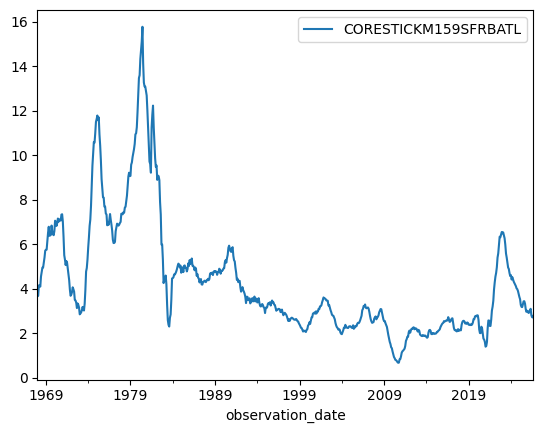

In [29]:
import pandas as pd
import matplotlib

path = "../../data/FRED/CORESTICKM159SFRBATL.csv"
df1 = pd.read_csv(path, index_col=0, parse_dates=True)

df1.plot()

<Axes: xlabel='observation_date'>

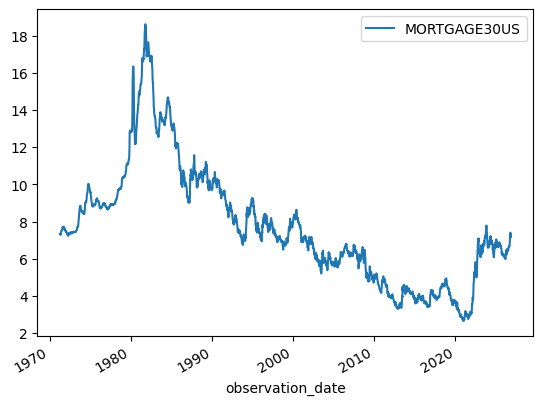

In [30]:
path2 = "../../data/FRED/MORTGAGE30US.csv"
df2 = pd.read_csv(path2, index_col=0, parse_dates=True)

df2.plot()

## Parse dates to join time series

In [34]:
import jinja2

df = pd.concat([df1,df2], axis=1, join="inner")

,CORESTICKM159SFRBATL,MORTGAGE30US
observation_date,,
2012-11-01 00:00:00,2.195661,3.390000
2013-08-01 00:00:00,1.911745,4.390000
2014-05-01 00:00:00,2.127518,4.290000
2015-10-01 00:00:00,2.335492,3.850000
2016-09-01 00:00:00,2.624799,3.460000
2016-12-01 00:00:00,2.585286,4.080000
2017-06-01 00:00:00,2.122109,3.940000
2018-02-01 00:00:00,2.123101,4.220000
2018-03-01 00:00:00,2.366926,4.430000


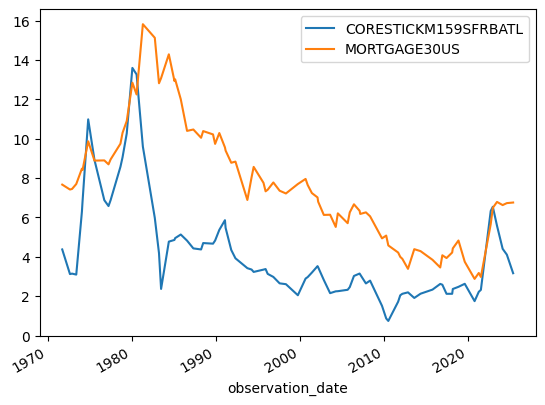

In [36]:
df.plot()
df.tail(20).style

,CORESTICKM159SFRBATL,MORTGAGE30US
observation_date,,
2024-11-21 00:00:00,nan,6.840000
2024-11-27 00:00:00,nan,6.810000
2024-12-01 00:00:00,3.746553,nan
2024-12-05 00:00:00,nan,6.690000
2024-12-12 00:00:00,nan,6.600000
2024-12-19 00:00:00,nan,6.720000
2024-12-26 00:00:00,nan,6.850000
2025-01-01 00:00:00,3.625276,nan
2025-01-02 00:00:00,nan,6.910000


## Inner join vs outer join

,CORESTICKM159SFRBATL,MORTGAGE30US
observation_date,,
1971-10-01,4.376577,7.67
1972-09-01,3.124726,7.42
...,...,...
2024-08-01,4.112096,6.73
2025-05-01,3.159131,6.76


## Interpolate missing values

In [40]:
df = pd.concat([df1, df2], axis=1, sort=True, join='outer')
df.tail(20)

,CORESTICKM159SFRBATL,MORTGAGE30US
observation_date,,
2026-07-09,NaN,6.49
2026-07-16,NaN,6.55
2026-07-23,NaN,6.58
2026-07-30,NaN,6.66
2026-08-01,2.700641,NaN
2026-08-06,NaN,6.69
2026-08-13,NaN,6.67
2026-08-20,NaN,6.65
2026-08-27,NaN,6.66


,CORESTICKM159SFRBATL,MORTGAGE30US
observation_date,,
1968-01-01,3.651861,NaN
1968-02-01,3.673819,NaN
...,...,...
2025-09-04,3.419811,6.50
2025-09-11,3.419811,6.35


In [41]:
df = df.interpolate(method='linear')
df.tail(20)

,CORESTICKM159SFRBATL,MORTGAGE30US
observation_date,,
2026-07-09,2.710771,6.490
2026-07-16,2.708238,6.550
2026-07-23,2.705706,6.580
2026-07-30,2.703174,6.660
2026-08-01,2.700641,6.675
2026-08-06,2.715819,6.690
2026-08-13,2.730996,6.670
2026-08-20,2.746174,6.650
2026-08-27,2.761351,6.660


<Axes: xlabel='observation_date'>

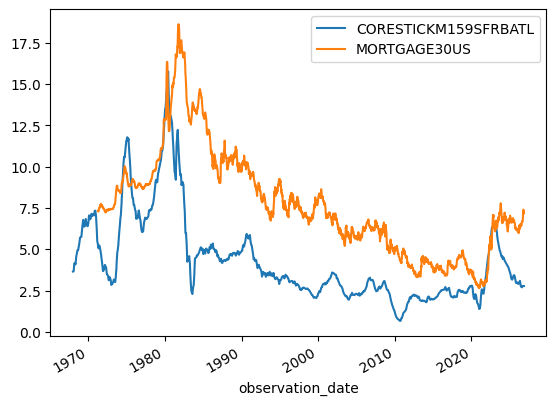

In [42]:
df.plot()

## Iterate for seamless load

,CORESTICKM159SFRBATL,MORTGAGE30US,FEDFUNDS,T10YIE,UNRATE
observation_date,,,,,
1948-01-01,NaN,NaN,NaN,NaN,3.4
1948-02-01,NaN,NaN,NaN,NaN,3.8
...,...,...,...,...,...
2025-09-11,NaN,6.35,NaN,2.34,NaN
2025-09-12,NaN,NaN,NaN,2.36,NaN


,CORESTICKM159SFRBATL,MORTGAGE30US,FEDFUNDS,T10YIE,UNRATE
observation_date,,,,,
1948-01-01,NaN,NaN,NaN,NaN,3.4
1948-02-01,NaN,NaN,NaN,NaN,3.8
...,...,...,...,...,...
2025-09-11,3.419811,6.35,4.33,2.34,4.3
2025-09-12,3.419811,6.35,4.33,2.36,4.3


## Export data

,CORESTICKM159SFRBATL,MORTGAGE30US,FEDFUNDS,T10YIE,UNRATE
date,,,,,
1948-01-01,NaN,NaN,NaN,NaN,3.4
1948-02-01,NaN,NaN,NaN,NaN,3.8
...,...,...,...,...,...
2025-09-11,3.419811,6.35,4.33,2.34,4.3
2025-09-12,3.419811,6.35,4.33,2.36,4.3


,CPI,MR,FFR,INF10,UNRT
date,,,,,
1948-01-01,NaN,NaN,NaN,NaN,3.4
1948-02-01,NaN,NaN,NaN,NaN,3.8
...,...,...,...,...,...
2025-09-11,3.419811,6.35,4.33,2.34,4.3
2025-09-12,3.419811,6.35,4.33,2.36,4.3
